# 

In [1]:
words = open("makemore/names.txt", "r").read().splitlines()
words[:10]

print(len(words))  # How many names exist in this dataset?
print(min(len(w) for w in words))  # What is the shortest name.
print(max(len(w) for w in words))  # What is the longest name.

32033
2
15


In [2]:

b = {}

for w in words:
    # Creating the Bigram of the beginning and last letter.
    ch = ["<S>"] + list(w) + ["<E>"] # w ---> 'emma'   BUT   list(w) ---> ['e', 'm', 'm', 'a']

    # For every word, I get the first character and its next.
    for ch1, ch2 in zip(ch[0:], ch[1:]):

        # Checking the number of times that a Bigram appears.
        bigram = (ch1, ch2)
        b[bigram] = b.get(bigram, 0) + 1 # Just counting bigrams and seeing how often they occur.
        
        # print(ch1, ch2)

# print(f"{b}\n")
b

{('<S>', 'e'): 1531,
 ('e', 'm'): 769,
 ('m', 'm'): 168,
 ('m', 'a'): 2590,
 ('a', '<E>'): 6640,
 ('<S>', 'o'): 394,
 ('o', 'l'): 619,
 ('l', 'i'): 2480,
 ('i', 'v'): 269,
 ('v', 'i'): 911,
 ('i', 'a'): 2445,
 ('<S>', 'a'): 4410,
 ('a', 'v'): 834,
 ('v', 'a'): 642,
 ('<S>', 'i'): 591,
 ('i', 's'): 1316,
 ('s', 'a'): 1201,
 ('a', 'b'): 541,
 ('b', 'e'): 655,
 ('e', 'l'): 3248,
 ('l', 'l'): 1345,
 ('l', 'a'): 2623,
 ('<S>', 's'): 2055,
 ('s', 'o'): 531,
 ('o', 'p'): 95,
 ('p', 'h'): 204,
 ('h', 'i'): 729,
 ('<S>', 'c'): 1542,
 ('c', 'h'): 664,
 ('h', 'a'): 2244,
 ('a', 'r'): 3264,
 ('r', 'l'): 413,
 ('l', 'o'): 692,
 ('o', 't'): 118,
 ('t', 't'): 374,
 ('t', 'e'): 716,
 ('e', '<E>'): 3983,
 ('<S>', 'm'): 2538,
 ('m', 'i'): 1256,
 ('a', 'm'): 1634,
 ('m', 'e'): 818,
 ('<S>', 'h'): 874,
 ('r', 'p'): 14,
 ('p', 'e'): 197,
 ('e', 'r'): 1958,
 ('r', '<E>'): 1377,
 ('e', 'v'): 463,
 ('v', 'e'): 568,
 ('l', 'y'): 1588,
 ('y', 'n'): 1826,
 ('n', '<E>'): 6763,
 ('b', 'i'): 217,
 ('i', 'g'): 428,


In [10]:
sorted(b.items(), key=lambda kv: -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [11]:
# ---[Instead of keeping this information in a Dictionary, why not store it in a 2D array?]--------------------------------------------

import torch

N = torch.zeros((28,28), dtype=torch.int32)
N

# N[1, 3] = 34


# Getting all the characters in the dataset i.e. words

# Creating a lookup table to convert the characters into integers.
chars = sorted(list(set(''.join(words))))
stoi =  {s:i for i,s in enumerate(chars)}
stoi['<S>'] = 26
stoi['<E>'] = 27
stoi


for w in words:
    ch = ["<S>"] + list(w) + ["<E>"]
    for ch1, ch2 in zip(ch, ch[1:]):
        # bigram = (ch1, ch2)
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2 ] += 1

N # But this looks ugly, let us visualise this more clearly.


tensor([[ 556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568, 2528,
         1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,  182,
         2050,  435,    0, 6640],
        [ 321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,  103,
            0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,    0,
           83,    0,    0,  114],
        [ 815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,  116,
            0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,    3,
          104,    4,    0,   97],
        [1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,   60,
           30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,    0,
          317,    1,    0,  516],
        [ 679,  121,  153,  384, 1271,   82,  125,  152,  818,   55,  178, 3248,
          769, 2675,  269,   83,   14, 1958,  861,  580,   69,  463,   50,  132,
         1070,  181,    0, 3983],
        [ 242,    0,

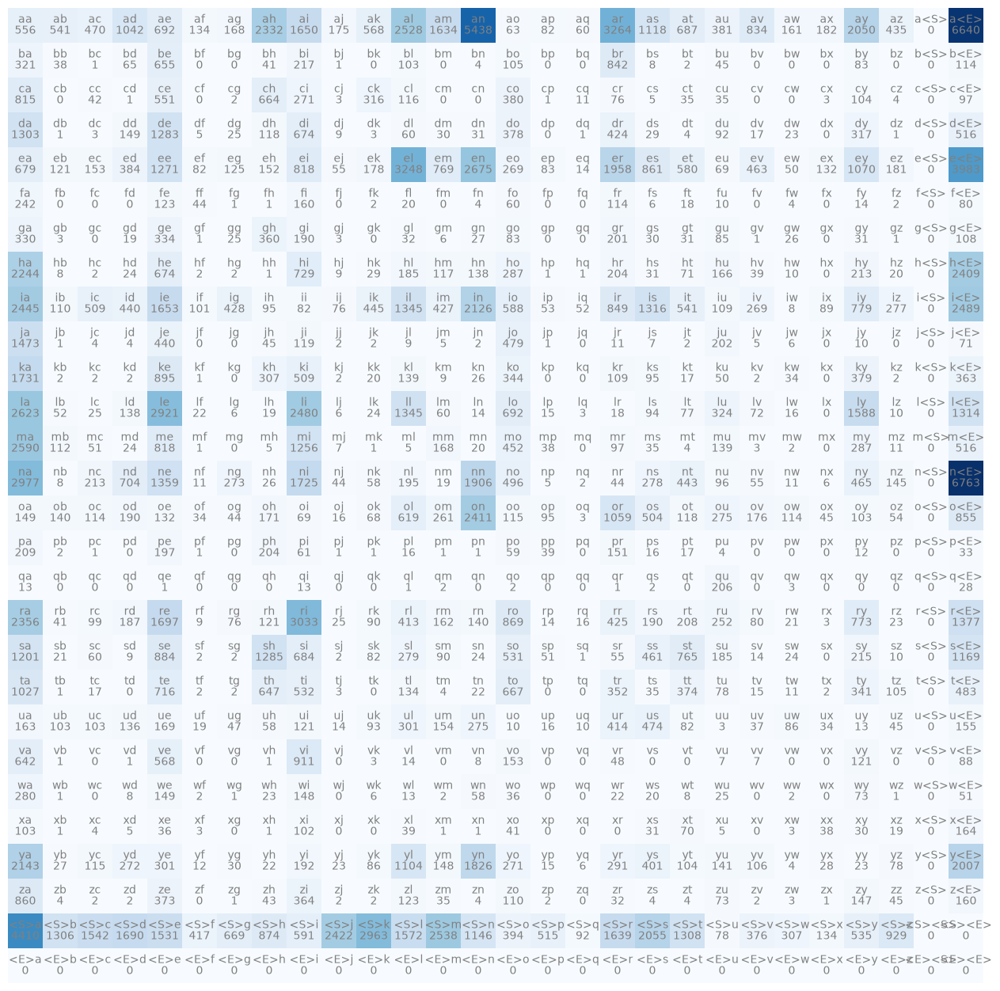

In [12]:
# ---[Visualising with matplotlib]----------------------------------------------------------------------------------------------
#
# itos = {i:s for s,i in stoi.items()}
# itos
#
# import matplotlib.pyplot as plt
# %matplotlib inline
#
# plt.figure(figsize=(16,16))
# plt.imshow(N, cmap='Blues')
# for i in range(28):
#     for j in range(28):
#         chstr = itos[i] + itos[j]
#         plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
#         plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')
# plt.axis('off');
# plt.show()
#

itos = {i:s for s,i in stoi.items()}

import matplotlib.pyplot as plt
%matplotlib inline

fig, ax = plt.subplots(figsize=(16,16))  # ← changed
ax.imshow(N, cmap='Blues')               # ← changed

for i in range(28):
    for j in range(28):
        chstr = itos[i] + itos[j]
        ax.text(j, i, chstr, ha="center", va="bottom", color='gray')   # ← ax.text
        ax.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')  # ← ax.text

ax.axis('off')  # ← changed
plt.show()


In [13]:
# if yout look at the row where <E> starts and the column where <s> ends, they are completely zero, why not just remove them completely.
# hence modifying the code above.
# The logic behind this is that there is never and never will be a case where <E> will be the starting character and <S> be the ending character.
# Refactor the code to remove these unnecessaries.



import torch

# We are not going to have two special characters, we are going to have only one special character.
N = torch.zeros((27,27), dtype=torch.int32)

chars = sorted(list(set(''.join(words))))
stoi =  {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0   # Making this special character position zero and offsetting all the others would seem pleasing.
itos = {i:s for s,i in stoi.items()}
# itos


In [14]:
for w in words:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        # bigram = (ch1, ch2)
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2 ] += 1

N # But this looks ugly, let us visualise this more clearly.

tensor([[   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
         1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
          134,  535,  929],
        [6640,  556,  541,  470, 1042,  692,  134,  168, 2332, 1650,  175,  568,
         2528, 1634, 5438,   63,   82,   60, 3264, 1118,  687,  381,  834,  161,
          182, 2050,  435],
        [ 114,  321,   38,    1,   65,  655,    0,    0,   41,  217,    1,    0,
          103,    0,    4,  105,    0,    0,  842,    8,    2,   45,    0,    0,
            0,   83,    0],
        [  97,  815,    0,   42,    1,  551,    0,    2,  664,  271,    3,  316,
          116,    0,    0,  380,    1,   11,   76,    5,   35,   35,    0,    0,
            3,  104,    4],
        [ 516, 1303,    1,    3,  149, 1283,    5,   25,  118,  674,    9,    3,
           60,   30,   31,  378,    0,    1,  424,   29,    4,   92,   17,   23,
            0,  317,    1],
        [3983,  679,  121,  153,  384, 1271,   82,

In [15]:
import matplotlib.pyplot as plt
%matplotlib inline

# fig, ax = plt.subplots(figsize=(16,16))  # ← changed
plt.figure(figsize=(16,16))
ax.imshow(N, cmap='Blues')               # ← changed

for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')   # ← ax.text
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray')  # ← ax.text

ax.axis('off'); # ← changed
# plt.show()

In [16]:
N[0] #Basically the first row.

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [17]:
# We are just going to follow the probability of these counts and just sample them out.
# But they are raw counts, let us convert them to probabilies.
# here we are only getting the summation of the First row of N. This will come in handy later on.

p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [18]:
p.sum()

tensor(1.)

In [19]:
# Now we an try to sample from the distribution, to sample from the distribution, we are going to use torch.multinomial.
# Torch.multinomial is just a fancy way of giving in probabilites and getting out integers.

g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [20]:
torch.multinomial(p, num_samples=200, replacement=True, generator=g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 1, 0,
        0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 2, 0,
        0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
        1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 2, 0, 1, 1, 2, 1, 1, 1,
        2, 0, 0, 1, 1, 0, 0, 2, 2, 0, 0, 0, 0, 0, 1, 2, 0, 0, 1, 0, 1, 0, 1, 0,
        2, 0, 1, 0, 0, 0, 0, 1])

In [23]:
# Now trying to sample names that we can get.
# We are able to use the model to sample new words/names.

g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix = 0
    while True: 
        p = N[ix].float()
        p = p / p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        # print(itos[ix])
        out.append(itos[ix])
    
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [24]:
P.shape

NameError: name 'P' is not defined

In [25]:
# Creating a matrix of Probabilities, P just like there is a matrix of numbers,N 
# Instead of calling them and computing all the time, which is wasteful,  

# We want to get probabilities for the indidvidual rows.
P = N.float()
P /= P.sum(1, keepdim=True) # broadcasting is happening here since it is a  (27, 27) / (27, 1). Look well into broadcasting coz it can become very buggy very fast.
# P.sum(1, keepdim=True) # sum(0) is the sum of every column(column-wise) and sum(1) gives the sum of every row(row_wise). the sum() function automatically lowers the dimension of what you are working on hence keepdim=True to maintain dimension.

In [26]:
g = torch.Generator().manual_seed(2147483647)

for i in range(10):
    out = []
    ix = 0
    while True: 
        p = N[ix].float()
        p = p / p.sum()
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        # print(itos[ix])
        out.append(itos[ix])
    
        if ix == 0:
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [27]:
# Now what I would like to do is to somehow evaluate the quality of this model.
# I want to summarize how good it is at predicting the training set.

for w in words:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        # N[ix1, ix2 ] += 1
        print(f'{ch1}{ch2}: {prob:.4f}') # just printing out the bigrams and the probabilities that the model assigned to them.

.e: 0.0478
em: 0.0377
mm: 0.0253
ma: 0.3899
a.: 0.1960
.o: 0.0123
ol: 0.0780
li: 0.1777
iv: 0.0152
vi: 0.3541
ia: 0.1381
a.: 0.1960
.a: 0.1377
av: 0.0246
va: 0.2495
a.: 0.1960
.i: 0.0184
is: 0.0743
sa: 0.1482
ab: 0.0160
be: 0.2476
el: 0.1590
ll: 0.0964
la: 0.1879
a.: 0.1960
.s: 0.0642
so: 0.0655
op: 0.0120
ph: 0.1988
hi: 0.0957
ia: 0.1381
a.: 0.1960
.c: 0.0481
ch: 0.1880
ha: 0.2946
ar: 0.0963
rl: 0.0325
lo: 0.0496
ot: 0.0149
tt: 0.0671
te: 0.1285
e.: 0.1950
.m: 0.0792
mi: 0.1891
ia: 0.1381
a.: 0.1960
.a: 0.1377
am: 0.0482
me: 0.1232
el: 0.1590
li: 0.1777
ia: 0.1381
a.: 0.1960
.h: 0.0273
ha: 0.2946
ar: 0.0963
rp: 0.0011
pe: 0.1920
er: 0.0959
r.: 0.1084
.e: 0.0478
ev: 0.0227
ve: 0.2208
el: 0.1590
ly: 0.1138
yn: 0.1868
n.: 0.3690
.a: 0.1377
ab: 0.0160
bi: 0.0820
ig: 0.0242
ga: 0.1713
ai: 0.0487
il: 0.0760
l.: 0.0941
.e: 0.0478
em: 0.0377
mi: 0.1891
il: 0.0760
ly: 0.1138
y.: 0.2053
.e: 0.0478
el: 0.1590
li: 0.1777
iz: 0.0156
za: 0.3586
ab: 0.0160
be: 0.2476
et: 0.0284
th: 0.1162
h.: 0.3163

In [29]:
# Now how can I summarise all these probabilities into a single number that measures the quality of this model.
# Something we can use here is MLE(Maximum Likelihood Estimation.)
# the Likelihood i just the product of all these probabilities.
# All that it does is tell us the probability tha dataset assigned by the model that we have trained.
# The product of these should be as high as possible when you are training a good model.

# But as you can see, the product of all these is something very very small, hence using log to find out the log probability.


# The loglikelihood is just the sum of the individual probabilities.
loglikelihood = 0
n = 0

for w in words[:]:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        loglikelihood += logprob
        n += 1
        # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}') 

# loglikelihood
# The closer to zero, the better.
print(f'Log likelihood: {loglikelihood:.4f}') # It maxes out at zero. The closer to zero, the better.
nll = -loglikelihood
print(f'Negative Log likelihood: {nll:.4f}') # The closer to zero, the better.
print(f'Normalised Log likelihood: {nll/n:.4f}') # Basically the average nll. The closer to zero, the better.

Log likelihood: -559891.7500
Negative Log likelihood: 559891.7500
Normalised Log likelihood: 2.4541


In [30]:
# you can search for the likelihood of the name that you want.
# For for some names like "andrejq", the model will print infinity.
# This is because the bigram jq has a zero percent chance of probability to happen.
# SO what we do here is called model smoothing, just add one to the whole damn, N i.e (N+1)
# Less the value --> Peaked. More the value --> Uniform the model is. Find that sweet spot.
P = (N+1000).float()
P /= P.sum(1, keepdim=True)

loglikelihood = 0
n = 0

# for w in words[:]:
for w in ["pisgah"]:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        loglikelihood += logprob
        n += 1
        print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}') 

print(f'Log likelihood: {loglikelihood:.4f}') # It maxes out at zero. The closer to zero, the better.
nll = -loglikelihood
print(f'Negative Log likelihood: {nll:.4f}') # The closer to zero, the better.
print(f'Normalised Log likelihood: {nll/n:.4f}') # Basically the average nll. The closer to zero, the better.

.p: 0.0257 -3.6627
pi: 0.0379 -3.2739
is: 0.0518 -2.9602
sg: 0.0285 -3.5564
ga: 0.0460 -3.0796
ah: 0.0547 -2.9054
h.: 0.0985 -2.3179
Log likelihood: -21.7560
Negative Log likelihood: 21.7560
Normalised Log likelihood: 3.1080


In [ ]:
# ---[APPROACH 2]--------------------------------------------------------------------

In [31]:
import torch
# import matplotlib.pyplot as plt


words = open("makemore/names.txt", "r").read().splitlines()
N = torch.zeros((27,27), dtype=torch.int32)
chars = sorted(list(set(''.join(words))))
stoi =  {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0   
itos = {i:s for s,i in stoi.items()}
# itos

xs, ys = [], []
for w in words[:1]:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        print(ch1, ch2)
        xs.append(ix1)
        ys.append(ix2)
        
xs = torch.tensor(xs)
ys = torch.tensor(ys)

. e
e m
m m
m a
a .


In [32]:
xs

tensor([ 0,  5, 13, 13,  1])

In [33]:
ys

tensor([ 5, 13, 13,  1,  0])

In [ ]:
# Now we are going to think through how we are going to feed these values through a neural network.
# It is not common to take integer values and multiply them throughout the neural network with weights.
# Instead, a common way of encoding these integers is using something known as One-Hot encoding. 
# In One-Hot encoding, we take aa number like 13 and we take a vector that is all zeroes except the 13th dimension which turns to one.
# for xs --> [0,1,1,0,0]

In [34]:
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [35]:
xenc.shape

torch.Size([5, 27])

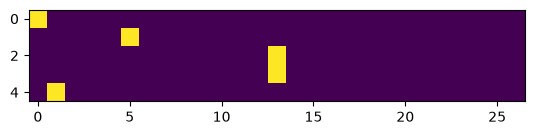

In [36]:
plt.imshow(xenc)

In [37]:
xenc.dtype # When plugging numbers in a neural net, we do not want them to be integers, we want them to be floats.

torch.float32

In [ ]:
# Now let us construct our first neuron, the neuron will look at these input vectors.

In [38]:
# Getting the weights.
# Randomly generate 27 neuraon's weights, each neuron receives 27 inputs.
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27), generator=g).float()

In [39]:
# the randn gave us both negative an positve values.
# exponentiating them makes them all positive. Look at its graph.

xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding.
logits = xenc @ W # predict logits/log-counts.
counts = logits.exp() # counts, equivalent to N
prob = counts / counts.sum(1, keepdim=True) #probabilities for the next character.
prob
# btw, the last 2 lines here are called 'softmax'.

tensor([[0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
         0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
         0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459],
        [0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
         0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
         0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472],
        [0.0312, 0.0737, 0.0484, 0.0333, 0.0674, 0.0200, 0.0263, 0.0249, 0.1226,
         0.0164, 0.0075, 0.0789, 0.0131, 0.0267, 0.0147, 0.0112, 0.0585, 0.0121,
         0.0650, 0.0058, 0.0208, 0.0078, 0.0133, 0.0203, 0.1204, 0.0469, 0.0126],
        [0.0312, 0.0737, 0.0484, 0.0333, 0.0674, 0.0200, 0.0263, 0.0249, 0.1226,
         0.0164, 0.0075, 0.0789, 0.0131, 0.0267, 0.0147, 0.0112, 0.0585, 0.0121,
         0.0650, 0.0058, 0.0208, 0.0078, 0.0133, 0.0203, 0.1204, 0.0469, 0.0126],
        [0.0150, 0.0086,

In [40]:
prob[0].sum()

tensor(1.0000)

In [41]:
nlls = torch.zeros(5)
for i in range(5):
    # i-th bigram.
    x = xs[i].item() # input character index.
    y = ys[i].item() # label character index.
    print(f'bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y}) ')
    print('input to the neural net:', x)
    print('output probablilities from the neural net:', prob[i])
    print('label (actual next character):', y)

    p = prob[i,y]
    print('probability assigned by the net to the correct character:', p.item())
    logp = torch.log(p)
    print('log likelihood:', logp.item())
    nll = -logp
    print('negative log likelihood:', nll.item())
    nlls[i] = nll
    print('-------------------------------------------------------------------------')
    # print('\n')

# print('=========================================================================')
print('\n')
print('\nAVERAGE NEGATIVE LOG LIKELIHOOD, i.e. loss =', nlls.mean().item())
print('\n')

bigram example 1: .e (indexes 0,5) 
input to the neural net: 0
output probablilities from the neural net: tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459])
label (actual next character): 5
probability assigned by the net to the correct character: 0.01228625513613224
log likelihood: -4.399273872375488
negative log likelihood: 4.399273872375488
-------------------------------------------------------------------------
bigram example 2: em (indexes 5,13) 
input to the neural net: 5
output probablilities from the neural net: tensor([0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
        0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
        0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472])
label (actual next character): 13
probabil

In [ ]:
# ---[OPTIMISATION]----------------------------------------------------

In [42]:
# randomly generate 27 neurons' weights. Each neuron receives 27 inputs.
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27), generator=g, requires_grad=True).float()

In [43]:
# Forward Pass.
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding.
logits = xenc @ W # predict logits/log-counts.
counts = logits.exp() # counts, equivalent to N
prob = counts / counts.sum(1, keepdim=True) #probabilities for the next character.
loss = -prob[torch.arange(5), ys].log().mean()
# loss
# prob

In [ ]:
# Now we are going to evaluate the loss, but we are going to use -ve log likelihood not MSE since we are doing classification not regression.

In [45]:
# what is the probability for each of the characters of the first bigram.
prob[0, 5], prob[1, 13], prob[2, 13], prob[3, 1], prob[4, 0]

(tensor(0.0123, grad_fn=<SelectBackward0>),
 tensor(0.0181, grad_fn=<SelectBackward0>),
 tensor(0.0267, grad_fn=<SelectBackward0>),
 tensor(0.0737, grad_fn=<SelectBackward0>),
 tensor(0.0150, grad_fn=<SelectBackward0>))

In [46]:
# which is the same as:
prob[torch.arange(5), ys]

tensor([0.0123, 0.0181, 0.0267, 0.0737, 0.0150], grad_fn=<IndexBackward0>)

In [47]:
# therefore the loss would be:
loss = -prob[torch.arange(5), ys].log().mean()
loss

tensor(3.7693, grad_fn=<NegBackward0>)

In [48]:
# Backward pass.
W.grad = None # set the gradient to zero.
loss.backward()

In [49]:
W.grad

tensor([[ 0.0121,  0.0020,  0.0025,  0.0008,  0.0034, -0.1975,  0.0005,  0.0046,
          0.0027,  0.0063,  0.0016,  0.0056,  0.0018,  0.0016,  0.0100,  0.0476,
          0.0121,  0.0005,  0.0050,  0.0011,  0.0068,  0.0022,  0.0006,  0.0040,
          0.0024,  0.0307,  0.0292],
        [-0.1970,  0.0017,  0.0079,  0.0020,  0.0121,  0.0062,  0.0217,  0.0026,
          0.0025,  0.0010,  0.0205,  0.0017,  0.0198,  0.0022,  0.0046,  0.0041,
          0.0082,  0.0016,  0.0180,  0.0106,  0.0093,  0.0062,  0.0010,  0.0066,
          0.0131,  0.0101,  0.0018],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000

In [50]:
# ---[Optimisation!!! but this time actually.]

In [51]:
import torch
import matplotlib.pyplot as plt

# Create the dataset.
words = open("makemore/names.txt", "r").read().splitlines()
N = torch.zeros((27,27), dtype=torch.int32)
chars = sorted(list(set(''.join(words))))
stoi =  {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0   
itos = {i:s for s,i in stoi.items()}
# itos

xs, ys = [], []

for w in words:
    chs = ["."] + list(w) + ["."]
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        # print(ch1, ch2)
        xs.append(ix1)
        ys.append(ix2)
        
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ',num)

number of examples:  228146


In [52]:
# Initialise the network.
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27), generator=g, requires_grad=True)

In [55]:
# Gradient descend.
for k in range(100): 
    
    # Forward Pass.
    xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding.
    logits = xenc @ W # predict logits/log-counts.
    counts = logits.exp() # counts, equivalent to N
    prob = counts / counts.sum(1, keepdim=True) #probabilities for the next character.
    loss = -prob[torch.arange(num), ys].log().mean()
    print(loss.item())

    # Backward pass.
    W.grad = None # set the gradient to zero.
    loss.backward()

    # Update.
    W.data += -1 * W.grad

2.9485762119293213
2.946942090988159
2.9453182220458984
2.94370436668396
2.9421002864837646
2.9405062198638916
2.938922166824341
2.937347173690796
2.9357821941375732
2.9342262744903564
2.932680368423462
2.9311437606811523
2.9296164512634277
2.928098201751709
2.926589012145996
2.925089120864868
2.923598051071167
2.9221155643463135
2.920642614364624
2.919177770614624
2.91772198677063
2.9162745475769043
2.9148361682891846
2.9134058952331543
2.9119837284088135
2.9105701446533203
2.909165143966675
2.9077680110931396
2.906378984451294
2.9049980640411377
2.903625011444092
2.9022600650787354
2.90090274810791
2.8995532989501953
2.898212194442749
2.8968780040740967
2.8955514430999756
2.894232749938965
2.8929216861724854
2.8916175365448
2.8903210163116455
2.8890321254730225
2.8877501487731934
2.8864753246307373
2.8852078914642334
2.8839471340179443
2.8826935291290283
2.8814470767974854
2.8802075386047363
2.878974437713623
2.877748727798462
2.8765296936035156
2.875316619873047
2.874110698699951
2.